# Notebook 01 — Leitura e análise exploratória

Lê o banco espectral, separa as colunas espectrais das de laboratório, descreve os atributos,
remove as amostras sem o atributo-alvo e salva os dados para o notebook 02.

**Entrada:** `dados/bssl.csv` (caminho em `config.py`) · **Saídas:** `resultados/dados_brutos.npz`, `resultados/df_limpo.pkl` e figuras `01_*.png`

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as cfg, utils

cfg.PASTA_FIG.mkdir(parents=True, exist_ok=True)

## 1. Leitura

In [2]:
df = pd.read_csv(cfg.ARQUIVO)
cols_esp, cols_ref = utils.identificar_colunas(df, cfg.PREFIXO)
wl_orig = utils.comprimentos_onda(cols_esp, cfg.PREFIXO)

print('Amostras:', df.shape[0])
print('Bandas espectrais:', len(cols_esp), f'({wl_orig.min():.0f} a {wl_orig.max():.0f} nm)')
print('Colunas de referência:', cols_ref)

Amostras: 900
Bandas espectrais: 431 (350 a 2500 nm)
Colunas de referência: ['id', 'argila', 'mo']


## 2. Estatística descritiva e valores faltantes

In [3]:
display(df[cols_ref].describe().round(2))

faltantes = pd.DataFrame({'faltantes': df[cols_ref].isna().sum(),
                          '%': (100 * df[cols_ref].isna().mean()).round(1)})
display(faltantes)

,argila,mo
count,860.00,900.00
mean,36.84,19.41
std,21.13,10.36
min,0.50,1.12
25%,19.37,11.76
50%,34.56,17.77
75%,52.49,24.58
max,100.00,77.52


,faltantes,%
id,0,0.0
argila,40,4.4
mo,0,0.0


## 3. Limpeza

Remove as amostras sem o atributo-alvo e as com bandas faltantes. `X` e `y` são definidos
**depois** da limpeza, com as linhas na mesma ordem de `df`.

In [4]:
n_antes = len(df)
df = df.dropna(subset=[cfg.COL_ALVO])
df = df[df[cols_esp].notna().all(axis=1)].reset_index(drop=True)
print(f'Amostras: {n_antes} -> {len(df)} após a limpeza')
print(f'Assimetria de {cfg.COL_ALVO}: {df[cfg.COL_ALVO].skew():.2f}')

X = df[cols_esp].to_numpy(dtype=float)       # reflectância bruta
y = df[cfg.COL_ALVO].to_numpy(dtype=float)
print('X:', X.shape, '| y:', y.shape)

Amostras: 900 -> 860 após a limpeza
Assimetria de argila: 0.41
X: (860, 431) | y: (860,)


## 4. Distribuição do atributo-alvo

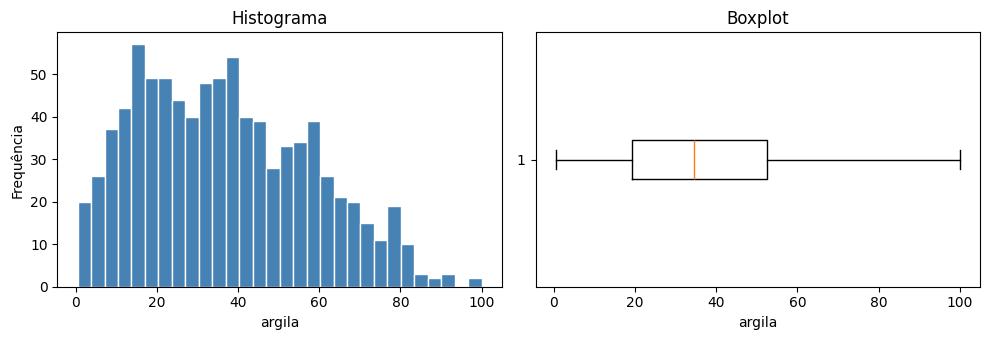

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].hist(y, bins=30, color='steelblue', edgecolor='white')
ax[0].set_xlabel(cfg.COL_ALVO); ax[0].set_ylabel('Frequência'); ax[0].set_title('Histograma')
ax[1].boxplot(y, vert=False)
ax[1].set_xlabel(cfg.COL_ALVO); ax[1].set_title('Boxplot')
plt.tight_layout(); utils.salva_figura(fig, '01_distribuicao_alvo.png'); plt.show()

## 5. Espectros brutos

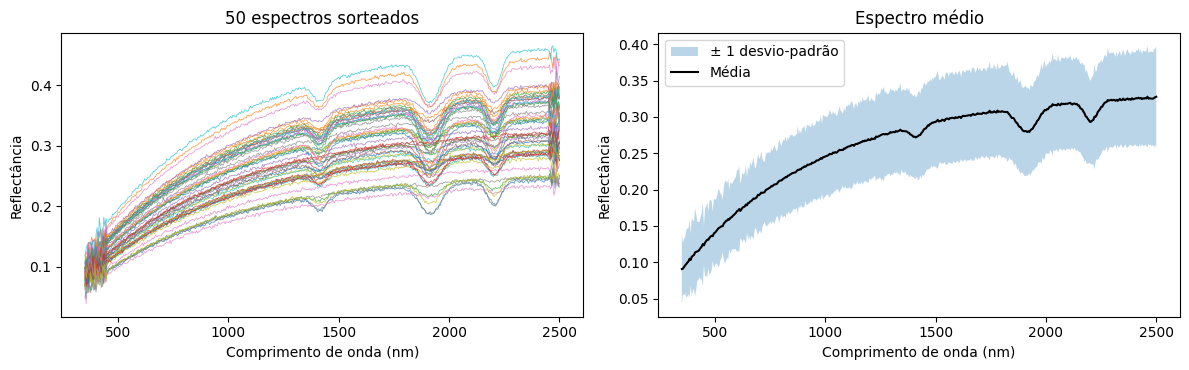

In [6]:
rng = np.random.default_rng(cfg.SEED)
amostra = rng.choice(len(X), min(50, len(X)), replace=False)
media, dp = X.mean(axis=0), X.std(axis=0)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(wl_orig, X[amostra].T, lw=0.6, alpha=0.7)
ax[0].set_title('50 espectros sorteados')
ax[1].fill_between(wl_orig, media - dp, media + dp, alpha=0.3, label='± 1 desvio-padrão')
ax[1].plot(wl_orig, media, color='black', label='Média')
ax[1].set_title('Espectro médio'); ax[1].legend()
for a in ax:
    a.set_xlabel('Comprimento de onda (nm)'); a.set_ylabel('Reflectância')
plt.tight_layout(); utils.salva_figura(fig, '01_espectros_brutos.png'); plt.show()

## 6. Correlação de cada banda com o atributo-alvo

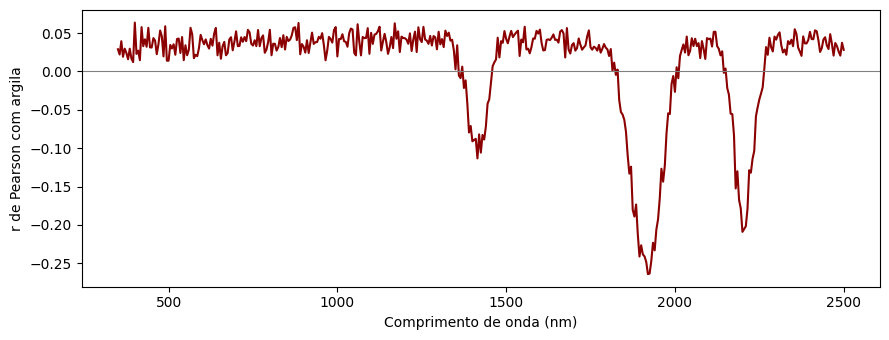

Maior |r|: 0.26 em 1920 nm


In [7]:
Xc = X - X.mean(axis=0)
yc = y - y.mean()
corr = (Xc * yc[:, None]).sum(axis=0) / (np.sqrt((Xc ** 2).sum(axis=0)) * np.sqrt((yc ** 2).sum()))

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(wl_orig, corr, color='darkred')
ax.axhline(0, color='gray', lw=0.8)
ax.set_xlabel('Comprimento de onda (nm)'); ax.set_ylabel(f'r de Pearson com {cfg.COL_ALVO}')
plt.tight_layout(); utils.salva_figura(fig, '01_correlacao_bandas.png'); plt.show()
print(f'Maior |r|: {np.abs(corr).max():.2f} em {wl_orig[np.abs(corr).argmax()]:.0f} nm')

## 7. Salvar

In [8]:
cfg.PASTA.mkdir(parents=True, exist_ok=True)
np.savez(cfg.PASTA / 'dados_brutos.npz', X=X, y=y, wl_orig=wl_orig)
df.to_pickle(cfg.PASTA / 'df_limpo.pkl')
print('Salvos: dados_brutos.npz e df_limpo.pkl em', cfg.PASTA)

Salvos: dados_brutos.npz e df_limpo.pkl em resultados
